# 03 – Charts
**Hotel Booking Analytics – Capstone Project** · Junaidi Abdul Rahim (Arjun)

Draws the report charts from the tables made in 02_Analyse. Every chart is shown here and saved as a PNG in `images/charts/`.
Colours: **City Hotel = blue, Resort Hotel = orange**.

## Step 1 – Set-up: style, colours and helper functions

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt          # drawing
import matplotlib.dates as mdates        # date axis formatting
import matplotlib.ticker as mt           # % and euro axis formatting
%matplotlib inline

os.makedirs('../images/charts', exist_ok=True)                 # folder for the PNG files
T = pd.read_pickle('../data/processed/tables.pkl')                # tables from notebook 02

BLUE, ORANGE, GREEN, RED, AMBER, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#eda100', '#8a8984'
HC = {'City Hotel': BLUE, 'Resort Hotel': ORANGE}    # one colour per hotel, used everywhere

plt.rcParams.update({'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,   # remove top/right borders
                     'axes.edgecolor': '#bbb', 'axes.grid': True, 'grid.color': '#eee',
                     'axes.axisbelow': True, 'axes.titleweight': 'bold',
                     'axes.titlesize': 13, 'axes.titlelocation': 'left'})

pct = mt.PercentFormatter(1, 0)                                              # 0.37 -> 37%
eur = mt.FuncFormatter(lambda v, p: f'€{v/1e6:.1f}M' if v >= 1e6 else f'€{v/1e3:.0f}K')   # euro labels

def save(f, n):
    # tidy the layout, save as PNG and show it in the notebook
    f.tight_layout()
    f.savefig(f'../images/charts/{n}.png', dpi=160)
    plt.show()

def hbar(df, col, val, title, n, fmt=pct, color=BLUE, label_fmt='{:.0%}'):
    # horizontal bar chart with the value written at the end of each bar
    d = df[::-1]                                                     # reverse so the first row is on top
    f, a = plt.subplots(figsize=(8, 0.45 * len(d) + 1.2))
    a.barh(d[col], d[val], color=color, height=0.6)
    a.xaxis.set_major_formatter(fmt)
    a.set_title(title)
    a.grid(axis='y', visible=False)
    for y, v in zip(d[col], d[val]):
        a.text(v, y, ' ' + label_fmt.format(v), va='center', fontsize=10, color='#333')   # value label
    save(f, n)

## Chart 1 – Monthly bookings by hotel

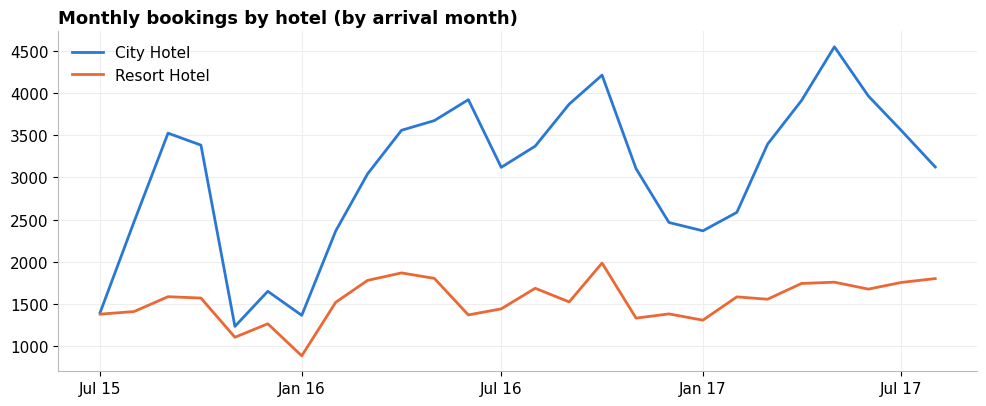

In [2]:
m = T['monthly']
f, a = plt.subplots(figsize=(10, 4.2))
for h, c in HC.items():
    s = m[m.hotel == h]
    a.plot(pd.to_datetime(s.ym), s.bookings, color=c, lw=2, label=h)        # one line per hotel
a.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))             # tick every January and July
a.set_title('Monthly bookings by hotel (by arrival month)')
a.legend(frameon=False)
save(f, '01_monthly_bookings')

## Chart 2 – Monthly cancellation rate by hotel

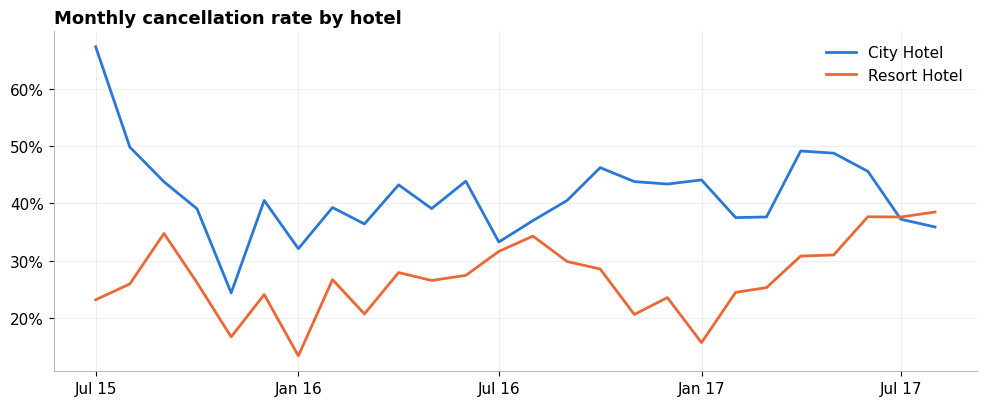

In [3]:
f, a = plt.subplots(figsize=(10, 4.2))
for h, c in HC.items():
    s = m[m.hotel == h]
    a.plot(pd.to_datetime(s.ym), s.cancel_rate, color=c, lw=2, label=h)
a.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
a.yaxis.set_major_formatter(pct)
a.set_title('Monthly cancellation rate by hotel')
a.legend(frameon=False)
save(f, '02_monthly_cancel')

## Charts 3–5 – What drives cancellations

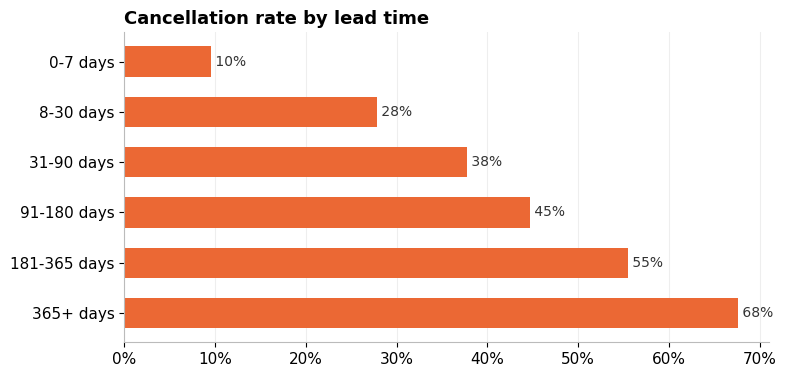

In [4]:
hbar(T['lead_band'], 'lead_time_band', 'cancel_rate', 'Cancellation rate by lead time', '03_lead', color=ORANGE)

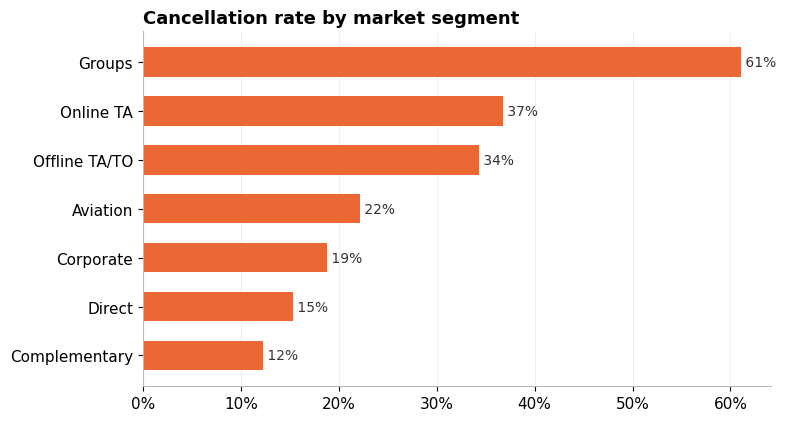

In [5]:
s = T['segment'][T['segment'].market_segment != 'Undefined']          # drop the tiny 'Undefined' group
hbar(s.sort_values('cancel_rate', ascending=False), 'market_segment', 'cancel_rate',
     'Cancellation rate by market segment', '04_segment', color=ORANGE)

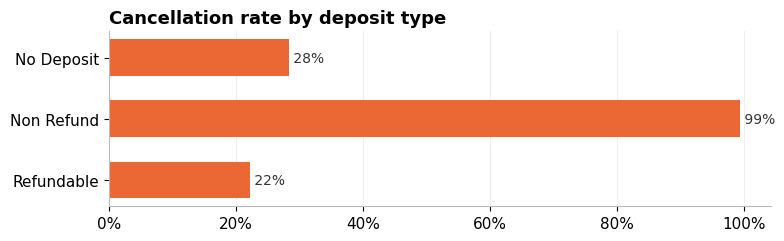

In [6]:
hbar(T['deposit'], 'deposit_type', 'cancel_rate', 'Cancellation rate by deposit type', '05_deposit', color=ORANGE)
# Note: 'Non Refund' at about 99% is a data quirk (likely group room blocks), not used for decisions

## Chart 6 – Average daily rate (ADR) by month

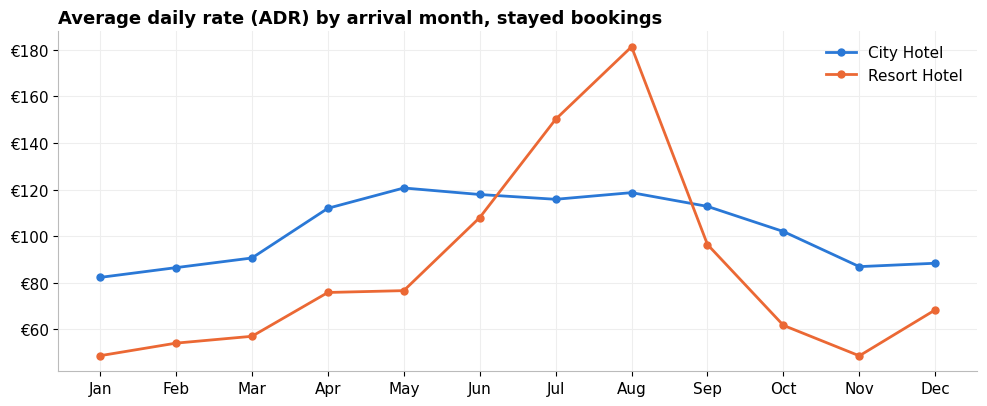

In [7]:
mo = T['moy']
f, a = plt.subplots(figsize=(10, 4.2))
for h, c in HC.items():
    s = mo[mo.hotel == h]
    a.plot(s.arrival_month_num, s.adr, color=c, lw=2, marker='o', ms=5, label=h)
a.set_xticks(range(1, 13))
a.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
a.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, p: f'€{v:.0f}'))
a.set_title('Average daily rate (ADR) by arrival month, stayed bookings')
a.legend(frameon=False)
save(f, '06_adr_month')

## Chart 7 – Realised vs lost revenue by hotel

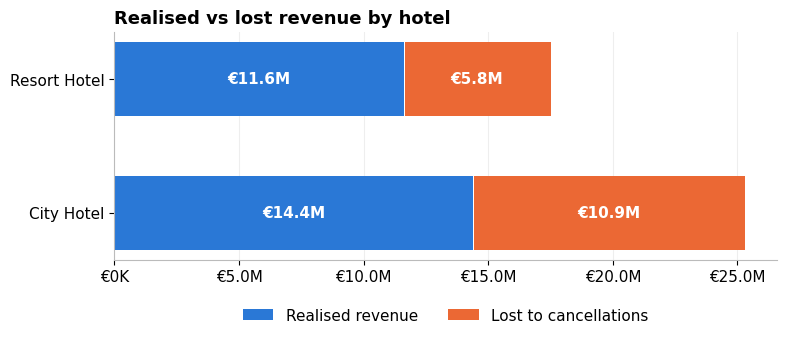

In [8]:
h = T['hotel']
f, a = plt.subplots(figsize=(8, 3.6))
a.barh(h.hotel, h.realised_rev, color=BLUE, height=0.55, label='Realised revenue')            # earned
a.barh(h.hotel, h.lost_rev, left=h.realised_rev + h.realised_rev.max() * 0.004,              # lost, stacked after a small gap
       color=ORANGE, height=0.55, label='Lost to cancellations')
for _, r in h.iterrows():
    a.text(r.realised_rev / 2, r.hotel, f'€{r.realised_rev/1e6:.1f}M', color='white', va='center', ha='center', fontweight='bold')
    a.text(r.realised_rev + r.lost_rev / 2, r.hotel, f'€{r.lost_rev/1e6:.1f}M', color='white', va='center', ha='center', fontweight='bold')
a.xaxis.set_major_formatter(eur)
a.set_title('Realised vs lost revenue by hotel')
a.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
a.grid(axis='y', visible=False)
save(f, '07_rev_lost')

## Chart 8 – Revenue forecast (actual, backtest and 12-month forecast)

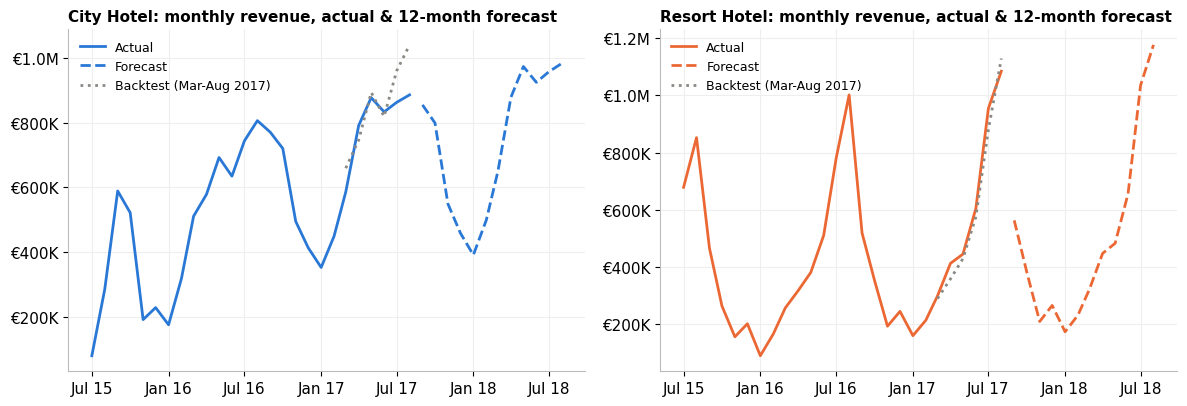

In [9]:
fc = T['forecast']
f, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (hn, c) in zip(axs, HC.items()):                                    # one panel per hotel
    s = fc[(fc.hotel == hn) & (fc.metric == 'realised_rev')]
    for t, st in [('Actual', '-'), ('Forecast', '--')]:                    # solid = actual, dashed = forecast
        q = s[s.type == t]
        a.plot(pd.to_datetime(q.month), q.value, st, color=c, lw=2, label=t)
    q = s[s.type == 'Backtest']                                            # dotted grey = backtest
    a.plot(pd.to_datetime(q.month), q.value, ':', color=GRAY, lw=2, label='Backtest (Mar-Aug 2017)')
    a.yaxis.set_major_formatter(eur)
    a.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    a.set_title(f'{hn}: monthly revenue, actual & 12-month forecast', fontsize=11)
    a.legend(frameon=False, fontsize=9)
save(f, '09_forecast')

## Chart 9 – Does the risk flag work?

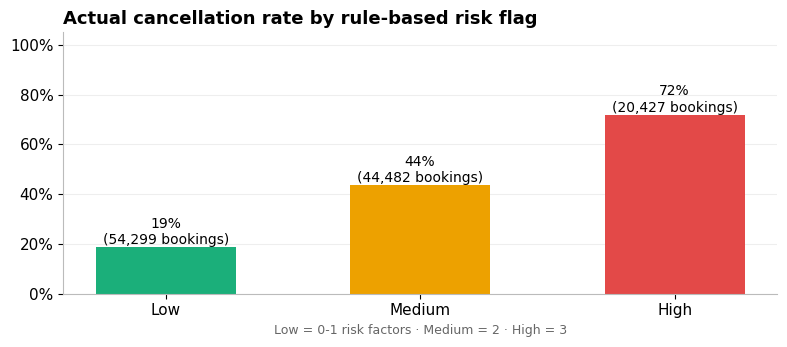

In [10]:
rb = T['risk_flag']
f, a = plt.subplots(figsize=(8, 3.6))
a.bar(rb.risk_flag, rb.actual_cancel_rate, color=[GREEN, AMBER, RED], width=0.55)    # Low, Medium, High
for x, v, nb in zip(rb.risk_flag, rb.actual_cancel_rate, rb.bookings):
    a.text(x, v, f'{v:.0%}\n({nb:,} bookings)', ha='center', va='bottom', fontsize=10)
a.set_ylim(0, 1.05)
a.yaxis.set_major_formatter(pct)
a.set_title('Actual cancellation rate by rule-based risk flag')
a.set_xlabel('Low = 0-1 risk factors · Medium = 2 · High = 3', fontsize=9, color='#666')
a.grid(axis='x', visible=False)
save(f, '10_risk_flag')

## Charts 10–11 – Guests

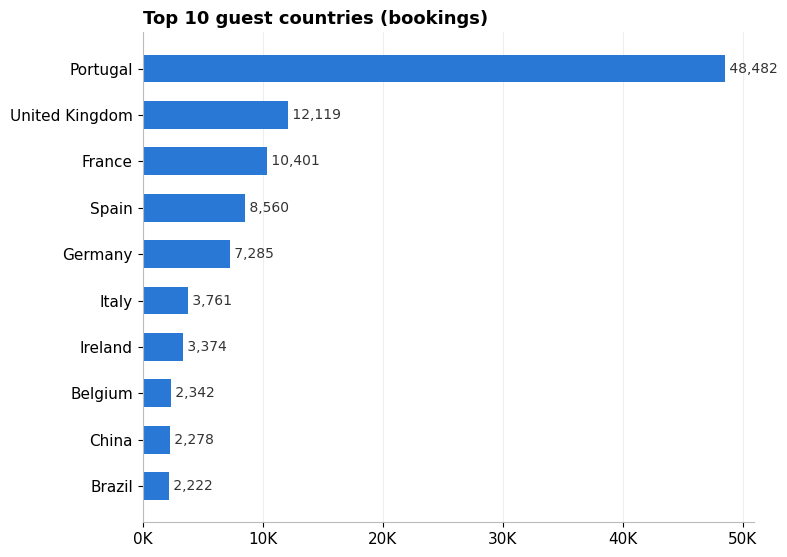

In [11]:
c = T['country'].sort_values('bookings', ascending=False)
hbar(c, 'country_name', 'bookings', 'Top 10 guest countries (bookings)', '11_country',
     fmt=mt.FuncFormatter(lambda v, p: f'{v/1000:.0f}K'), label_fmt='{:,.0f}')

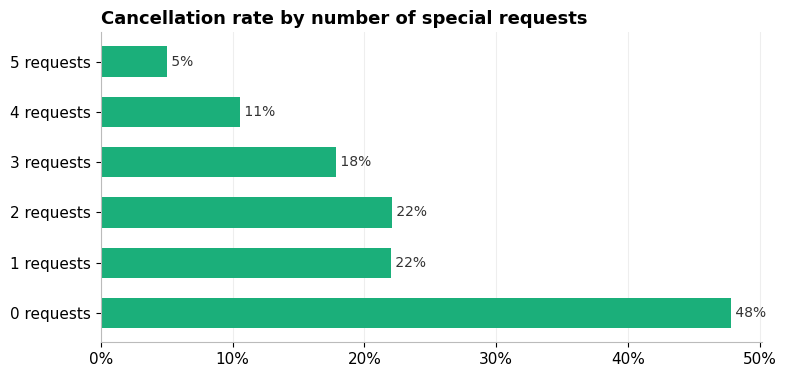

In [12]:
sr = T['special_req'].copy()
sr['lbl'] = sr.total_of_special_requests.astype(str) + ' requests'       # axis label text
hbar(sr[::-1], 'lbl', 'cancel_rate', 'Cancellation rate by number of special requests', '12_special', color=GREEN)

### Summary
11 charts saved in `images/charts/` and used in the Word report and the presentation. The same numbers appear in the Excel workbook and the Power BI dashboard.